# DreaMS embeddings and molecular families (first experiment)

**Context.** PRIORITY project (WUR). Meeting with Joana Tirana and Daniel Probst on 19 Oct 2026: embeddings for metabolomics, molecular families, and the DreaMS paper (Bushuiev et al., *Nature Biotechnology*, 2025).
**Author:** Vitória Maia

**Question.** Do DreaMS embeddings of MS/MS spectra put metabolites of the same molecular family close together? And does DreaMS similarity follow chemical structure better than the modified cosine that GNPS uses?

**Steps**
1. Take public GNPS molecular networking jobs on actinobacteria (*Salinispora*, *Streptomyces*) registered in the Paired Omics Data Platform.
2. Clean the spectra with the same quality rules as the DreaMS training data.
3. Compute embeddings with the **pre-trained** DreaMS model (no training in this notebook).
4. **Experiment A:** compare DreaMS neighbours and a DreaMS network with the GNPS molecular families.
5. **Experiment B:** compare DreaMS, modified cosine and a binned spectrum cosine with structural similarity (Tanimoto) on library-annotated spectra.

Each step is a script in `scripts/`. The notebook runs them for every dataset and shows the results. `RESULTS.md` has all the numbers in one page.

## 0. Setup

**One-time steps** (in a terminal, inside `priority-wur/dreams_molecular_families`). DreaMS needs Python 3.11 and fixed versions of numpy and torch, so it gets its own environment. [uv](https://docs.astral.sh/uv/) creates it.
```
git clone https://github.com/pluskal-lab/DreaMS.git .DreaMS
git -C .DreaMS checkout dbec3a0b514a99e5056cfccde4559fda8cfe8129
uv venv .dreams_env --python 3.11
uv pip install --python .dreams_env/Scripts/python.exe -e ./.DreaMS ipykernel nbclient
```
(On Mac/Linux, use `.dreams_env/bin/python`.) The first embedding run downloads the model weights (2.6 GB) from Hugging Face into `.DreaMS/`. Both folders are git-ignored.

**Data.** The GNPS jobs come from `data/raw/gnps/`, which `python -I scripts/download_data.py gnps` fills (run from the repository root). If a job is missing, `prepare_data.py` downloads it.

**Kernel.** Any Jupyter kernel with pandas works: the steps always run with the Python of `.dreams_env`. The simplest choice is the `.dreams_env` kernel itself.

In [1]:
import importlib.util
import os
import subprocess
import sys
import time
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

RUNS = ["duncan_salinispora", "crusemann_salstrep", "crusemann_streptomyces"]

EXPERIMENT_DIR = Path.cwd()
if not (EXPERIMENT_DIR / "scripts" / "common.py").exists():
    raise RuntimeError("Open this notebook from the dreams_molecular_families folder.")

# Python used for the steps: this kernel if it has DreaMS, otherwise .dreams_env.
if importlib.util.find_spec("dreams") is not None:
    PY = sys.executable
else:
    PY = str(EXPERIMENT_DIR / ".dreams_env" / ("Scripts/python.exe" if os.name == "nt" else "bin/python"))
    if not Path(PY).exists():
        raise RuntimeError("DreaMS environment not found. Do the one-time steps in section 0.")
print("Python used for the steps:", PY)


def step(script, *args, show=False):
    # Run one script and stop with its error message if it fails.
    start = time.time()
    result = subprocess.run(
        [PY, f"scripts/{script}", *args], capture_output=True, text=True,
        encoding="utf-8", errors="replace", env={**os.environ, "PYTHONUTF8": "1"},
    )
    if result.returncode != 0:
        print(result.stdout[-5000:], result.stderr[-5000:], sep="\n")
        raise RuntimeError(f"{script} {' '.join(args)} failed. Read the error above.")
    if show:
        print(result.stdout)
    print(f"done: {script} {' '.join(args)} ({time.time() - start:.0f} s)")


def results(run, name):
    return pd.read_parquet(EXPERIMENT_DIR / "runs" / run / "results" / f"{name}.parquet")


def side_by_side(name, key="metric", value="value"):
    # One summary table per run, merged into one table with a column per run.
    tables = []
    for run in RUNS:
        path = EXPERIMENT_DIR / "runs" / run / "results" / f"{name}.parquet"
        if path.exists():
            tables.append(pd.read_parquet(path).set_index(key)[value].rename(run))
    return pd.concat(tables, axis=1).fillna("")


ready = subprocess.run(
    [PY, "-c", "import torch, dreams; print('DreaMS is ready. GPU available:', torch.cuda.is_available())"],
    capture_output=True, text=True, check=True,
)
print(ready.stdout.strip())
pd.set_option("display.max_colwidth", 80)

Python used for the steps: C:\Users\iraci\github-Victoria125\priority-wur\dreams_molecular_families\.dreams_env\Scripts\python.exe


DreaMS is ready. GPU available: False


## 1. Data

| Run | Dataset | MassIVE (PoDP) | GNPS job |
|---|---|---|---|
| `duncan_salinispora` | *Salinispora*, Duncan et al. 2015 | MSV000079284 | `c22f44b1…` (METABOLOMICS-SNETS). Example job of the NPLinker docs, created by Justin van der Hooft (WUR) |
| `crusemann_salstrep` | *Salinispora* + *Streptomyces*, Crüsemann et al. 2017 | MSV000078836 | `9360fa51…` (METABOLOMICS-SNETS) |
| `crusemann_streptomyces` | *Streptomyces*, Crüsemann et al. 2017 | MSV000078839 | `840eadb0…` (METABOLOMICS-SNETS-V2) |

All three are the GNPS jobs that the Paired Omics Data Platform links to genomes, so the spectra can later be connected to BGCs with NPLinker. The two Crüsemann jobs overlap: the SalStrep job also re-analyses MSV000078839.

**Molecular families.** GNPS connects two spectra when their modified cosine is high enough. Each connected group is a molecular family (`componentindex`). Spectra without connections are singletons.

**Cleaning.** We keep only spectra that follow DreaMS "format A", the format of the data DreaMS was pre-trained on: charge +1, precursor m/z ≤ 1000, at least 3 peaks above 10% intensity, and max/min intensity ≥ 20. Peaks above the precursor m/z are removed, and at most 128 peaks are kept. The thresholds are at the top of `scripts/common.py`.

To add another dataset, add it to `RUNS` in `scripts/common.py` (any GNPS classic molecular networking job) and to `RUNS` in the setup cell.

In [2]:
for run in RUNS:
    step("prepare_data.py", "--run", run)

info = pd.DataFrame({run: pd.read_json(EXPERIMENT_DIR / "runs" / run / "results" / "run_info.json", typ="series") for run in RUNS})
display(info.drop(["run", "clean MGF md5"]))
display(side_by_side("00_filter_report", key="step", value="spectra"))

done: prepare_data.py --run duncan_salinispora (5 s)


done: prepare_data.py --run crusemann_salstrep (4 s)


done: prepare_data.py --run crusemann_streptomyces (9 s)


,duncan_salinispora,crusemann_salstrep,crusemann_streptomyces
dataset,"Salinispora, Duncan et al. 2015","Salinispora + Streptomyces, Crüsemann et al. 2017","Streptomyces, Crüsemann et al. 2017"
MassIVE dataset (PoDP),MSV000079284,MSV000078836,MSV000078839
GNPS task,c22f44b14a3d450eb836d607cb9521bb,9360fa514804487a9d39b7e7d7e6d514,840eadb054f74d74ae42152a08ed9628
GNPS workflow,METABOLOMICS-SNETS,METABOLOMICS-SNETS,METABOLOMICS-SNETS-V2
description,Salinispora_Molecular_Network_Duncanpaper_GenomeSequencedStrains_Grouping_in...,SalStrep only genome strains-newattributes-3-0.5 mmp4+kate_extractor_rerun,Streptomyces MassIVE
MassIVE datasets in the GNPS job,MSV000079484,MSV000078839,MSV000078839
fragment tolerance used by GNPS (Da),0.3,0.5,0.5
min cosine for GNPS edges,0.5,0.5,0.7
min matched peaks for GNPS edges,6,4,6
spectra read,25935,124950,433081


,duncan_salinispora,crusemann_salstrep,crusemann_streptomyces
step,,,
read from GNPS,25935.0,124950.0,433081.0
removed: no peaks below the precursor m/z (looks like noise),9966.0,,
removed: intensity range too small (max/min < 20),9477.0,1542.0,52.0
removed: fewer than 3 peaks above 10% intensity,2404.0,395.0,285.0
removed: charge is not +1,1074.0,532.0,416.0
removed: precursor m/z above 1000,111.0,92.0,108.0
kept for DreaMS,2903.0,3685.0,1973.0
removed: empty spectrum (no peaks at all),,118704.0,430247.0


## 2. DreaMS embeddings

We use the pre-trained `DreaMS_embedding` model. It gives one vector of 1024 numbers per spectrum. Spectra that DreaMS sees as similar get vectors that point in a similar direction (high cosine similarity).

On a laptop CPU this takes about 4 spectra per second. The embeddings are saved in `runs/<run>/data/dreams_embeddings.npy` and are only computed again if the cleaned spectra change.

In [3]:
for run in RUNS:
    step("embed_dreams.py", "--run", run)

display(pd.DataFrame({run: pd.read_json(EXPERIMENT_DIR / "runs" / run / "data" / "dreams_embeddings.json", typ="series") for run in RUNS}))

done: embed_dreams.py --run duncan_salinispora (1 s)


done: embed_dreams.py --run crusemann_salstrep (1 s)


done: embed_dreams.py --run crusemann_streptomyces (1 s)


,duncan_salinispora,crusemann_salstrep,crusemann_streptomyces
clean_mgf_md5,0ef8edd809fb5c82ed3e158a7a34113c,ec022e0c31db62424c676006ba9f65c4,66919e49a60f690f887701b1ff30aba9
shape,"[2903, 1024]","[3685, 1024]","[1973, 1024]"
model,"DreaMS_embedding (pre-trained, no fine-tuning)","DreaMS_embedding (pre-trained, no fine-tuning)","DreaMS_embedding (pre-trained, no fine-tuning)"
dreams_commit,dbec3a0b514a99e5056cfccde4559fda8cfe8129,dbec3a0b514a99e5056cfccde4559fda8cfe8129,dbec3a0b514a99e5056cfccde4559fda8cfe8129
device,CPU,CPU,CPU
seconds,1171,1745,864
computed_on,2026-11-02T18:11:52,2026-11-02T18:42:34,2026-11-02T18:57:44
machine,Windows-10-10.0.26200-SP0,Windows-10-10.0.26200-SP0,Windows-10-10.0.26200-SP0


## 3. Experiment A: molecular families

- **A1. Neighbours.** For each spectrum in a GNPS family with at least 3 members, we look at its 5 nearest neighbours in DreaMS space. *Family recovery@5* = family partners found, divided by the best possible number. Three baselines: the cosine of binned spectra (1 Da bins, no learning), neighbours chosen only by precursor m/z, and random neighbours.
- **A2. GNPS edges.** Pairs connected in the GNPS network should have a higher DreaMS similarity than random pairs.
- **A3. DreaMS network.** Each spectrum is linked to its 3 nearest neighbours if the DreaMS similarity is at least 0.7 (as in the DreaMS networking tutorial). We compare the resulting families with the GNPS families (AMI/ARI). DreaMS links that involve GNPS singletons are saved in `results/exp_a_new_links.parquet`. They are hypotheses to check by hand, not results.
- **A4. Network thresholds.** The same DreaMS network with thresholds from 0.6 to 0.95, to see how the size of the largest family and the agreement with GNPS change.

⚠️ GNPS families come from modified cosine, so this experiment measures **agreement with GNPS**, not truth. Experiment B uses chemical structures instead.

In [4]:
for run in RUNS:
    step("exp_a_families.py", "--run", run)

display(side_by_side("exp_a_summary"))
for run in RUNS:
    display(Markdown(f"**A4. DreaMS network thresholds: `{run}`**"))
    display(results(run, "exp_a_network_sweep"))

done: exp_a_families.py --run duncan_salinispora (42 s)


done: exp_a_families.py --run crusemann_salstrep (49 s)


done: exp_a_families.py --run crusemann_streptomyces (26 s)


,duncan_salinispora,crusemann_salstrep,crusemann_streptomyces
metric,,,
spectra used,"2,903","3,685","1,973"
spectra in GNPS families with >= 3 members,125,"2,138",757
A1 family recovery@5: DreaMS,0.59,0.656,0.72
A1 family recovery@5: binned spectrum cosine,0.602,0.776,0.693
A1 family recovery@5: precursor m/z only,0.121,0.343,0.232
A1 family recovery@5: random,0.007,0.017,0.01
A2 median DreaMS similarity: GNPS edges,0.738,0.681,0.717
A2 median DreaMS similarity: random pairs,0.426,0.206,0.193
A2 Spearman (GNPS cosine vs DreaMS similarity) on GNPS edges,0.263,0.567,0.452


**A4. DreaMS network thresholds: `duncan_salinispora`**

,threshold,edges,families (size >= 2),spectra in families,largest family,"AMI, all spectra","AMI, spectra in GNPS families",GNPS edges recovered (%)
0,0.60,6760,14,2805,2763,-0.000,0.266,41.9
1,0.70,6399,25,2681,2583,-0.001,0.539,34.9
2,0.80,5329,28,2353,2272,-0.010,0.362,23.2
3,0.85,3364,54,1761,1492,-0.009,0.292,13.5
4,0.90,544,113,559,65,0.020,0.086,3.8
5,0.95,1,1,2,2,-0.000,-0.000,0.0


**A4. DreaMS network thresholds: `crusemann_salstrep`**

,threshold,edges,families (size >= 2),spectra in families,largest family,"AMI, all spectra","AMI, spectra in GNPS families",GNPS edges recovered (%)
0,0.60,6653,75,3235,2974,0.100,0.153,29.9
1,0.70,3938,205,2218,588,0.486,0.599,22.6
2,0.80,1924,112,1090,388,0.423,0.450,13.4
3,0.85,1090,80,672,228,0.338,0.342,7.7
4,0.90,294,48,251,75,0.117,0.114,2.3
5,0.95,4,4,8,2,0.001,0.001,0.1


**A4. DreaMS network thresholds: `crusemann_streptomyces`**

,threshold,edges,families (size >= 2),spectra in families,largest family,"AMI, all spectra","AMI, spectra in GNPS families",GNPS edges recovered (%)
0,0.60,2948,62,1629,1336,0.121,0.257,42.8
1,0.70,1362,148,949,78,0.571,0.703,34.5
2,0.80,536,87,427,40,0.432,0.445,19.2
3,0.85,237,56,216,34,0.258,0.255,10.3
4,0.90,98,31,99,22,0.122,0.117,4.8
5,0.95,14,8,20,3,0.018,0.018,0.8


### `duncan_salinispora`

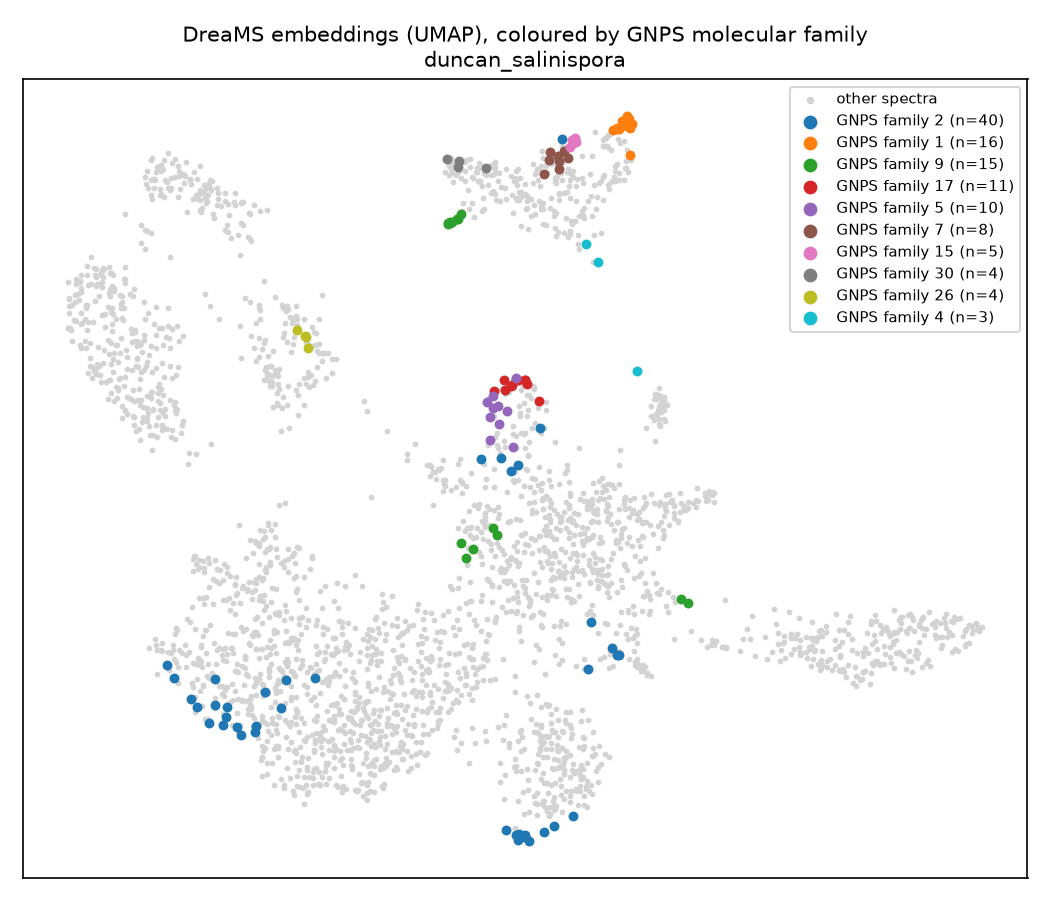

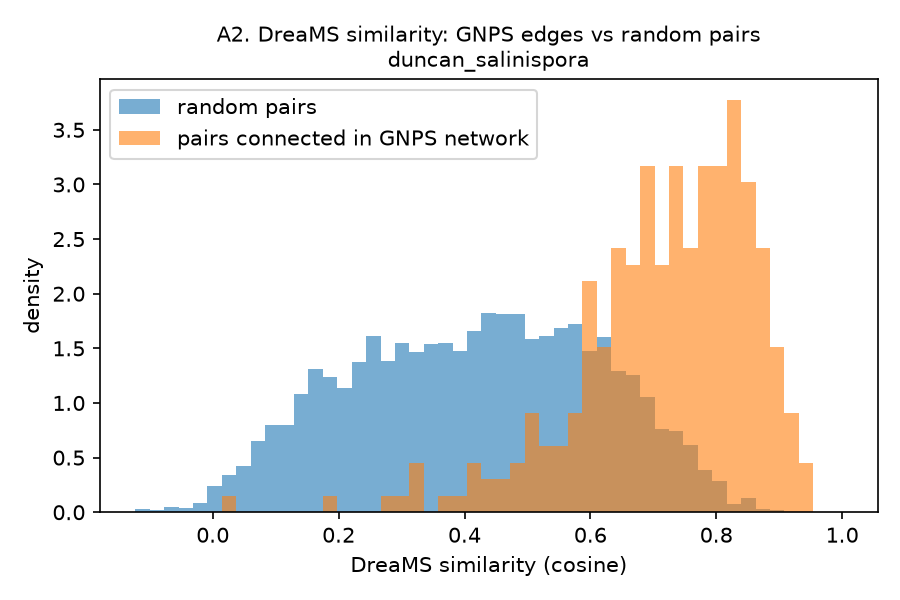

### `crusemann_salstrep`

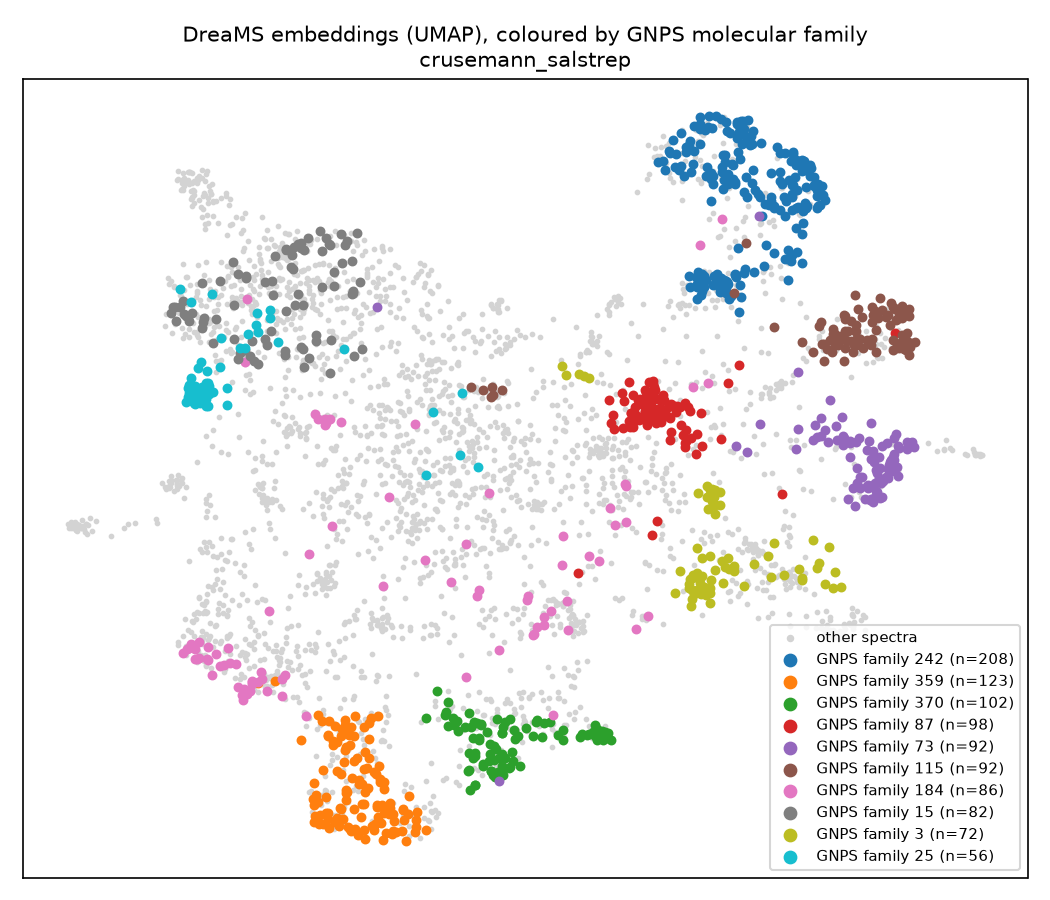

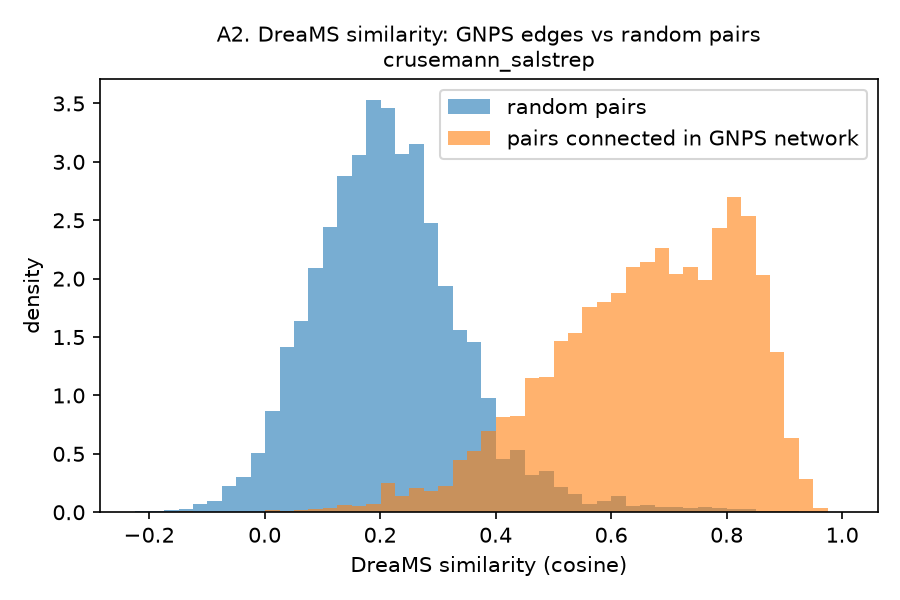

### `crusemann_streptomyces`

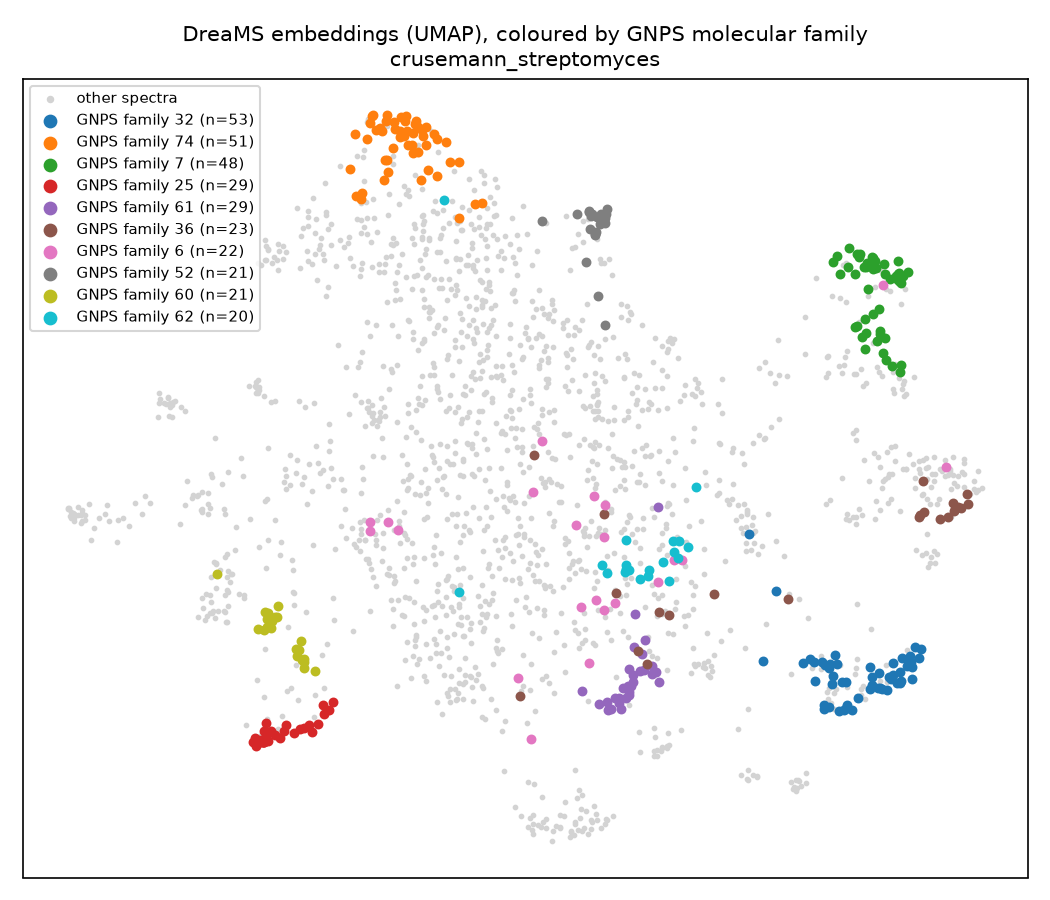

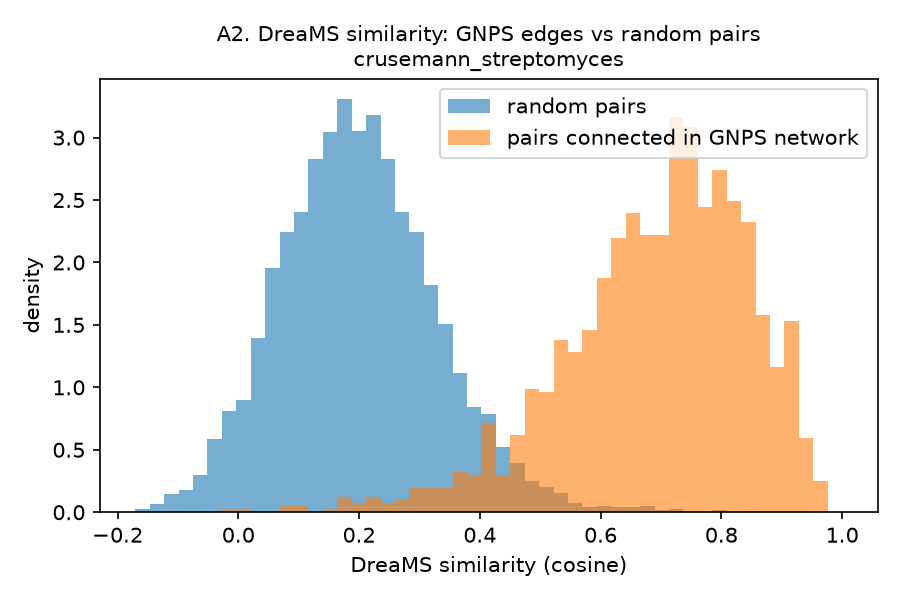

In [5]:
for run in RUNS:
    display(Markdown(f"### `{run}`"))
    display(Image(EXPERIMENT_DIR / "runs" / run / "results" / "exp_a_umap.png", width=560))
    display(Image(EXPERIMENT_DIR / "runs" / run / "results" / "exp_a_similarity_hist.png", width=460))

In [6]:
# DreaMS links that GNPS did not make (first rows). Look at the delta m/z
# (for example +14 = CH2, +16 = O) and at the library names.
for run in RUNS:
    display(Markdown(f"**New links: `{run}`**"))
    display(results(run, "exp_a_new_links").head(10))

**New links: `duncan_salinispora`**

,cluster_1,cluster_2,dreams_similarity,precursor_mz_1,precursor_mz_2,delta_mz,library_hit_1,library_hit_2,category
0,17607,17811,0.950,467.208,467.210,0.002,None,None,involves a GNPS singleton
1,21539,21540,0.949,541.291,541.291,0.000,None,None,involves a GNPS singleton
2,20323,20385,0.948,517.374,517.374,0.000,None,None,involves a GNPS singleton
3,20150,20159,0.947,513.214,513.215,0.001,None,Daunorubicin HCl (Daunomycin HCl),involves a GNPS singleton
4,21487,21491,0.947,539.550,539.550,0.000,Verteporfin (Visudyne),None,involves a GNPS singleton
5,18377,18378,0.946,483.203,483.203,0.000,Staurosporine,Staurosporine,involves a GNPS singleton
6,19191,19202,0.943,497.220,497.221,0.001,"MLS002153342-01!PD 168,077 maleate salt190383-31-4",None,involves a GNPS singleton
7,17957,17983,0.941,467.211,467.211,0.000,None,None,involves a GNPS singleton
8,23060,23061,0.941,579.298,579.298,0.000,None,None,involves a GNPS singleton
9,22623,22965,0.940,579.294,579.297,0.003,None,Spectral Match to Peonidin 3-O-glucoside cation from NIST14,involves a GNPS singleton


**New links: `crusemann_salstrep`**

,cluster_1,cluster_2,dreams_similarity,precursor_mz_1,precursor_mz_2,delta_mz,library_hit_1,library_hit_2,category
0,70922,71572,0.945,634.875,634.875,0.000,None,None,involves a GNPS singleton
1,71307,71527,0.942,634.875,634.876,0.001,None,None,involves a GNPS singleton
2,71348,71527,0.940,634.875,634.876,0.001,None,None,involves a GNPS singleton
3,71527,71572,0.935,634.876,634.875,-0.001,None,None,involves a GNPS singleton
4,60635,61001,0.934,566.887,566.888,0.001,None,None,involves a GNPS singleton
5,70922,71310,0.931,634.875,634.875,0.000,None,None,involves a GNPS singleton
6,60641,61001,0.931,566.887,566.888,0.001,None,None,involves a GNPS singleton
7,61001,71649,0.930,566.888,634.876,67.988,None,None,involves a GNPS singleton
8,48960,49171,0.929,498.903,498.902,-0.001,None,None,involves a GNPS singleton
9,61001,61745,0.929,566.888,566.891,0.003,None,None,involves a GNPS singleton


**New links: `crusemann_streptomyces`**

,cluster_1,cluster_2,dreams_similarity,precursor_mz_1,precursor_mz_2,delta_mz,library_hit_1,library_hit_2,category
0,378038,378041,0.937,740.514,740.515,0.001,None,None,involves a GNPS singleton
1,378041,378045,0.927,740.515,740.514,-0.001,None,None,involves a GNPS singleton
2,378042,378045,0.919,740.514,740.514,0.000,None,None,involves a GNPS singleton
3,378041,378047,0.917,740.515,740.514,-0.001,None,None,involves a GNPS singleton
4,378042,378047,0.906,740.514,740.514,0.000,None,None,involves a GNPS singleton
5,378042,378043,0.891,740.514,740.514,0.000,None,None,involves a GNPS singleton
6,316419,319033,0.881,646.143,649.512,3.369,None,None,involves a GNPS singleton
7,334202,334209,0.873,677.472,677.473,0.001,None,None,involves a GNPS singleton
8,24817,24818,0.871,408.310,408.311,0.001,Cholestan-3-One,Cholestan-3-One,involves a GNPS singleton
9,301993,302020,0.870,627.404,627.408,0.004,None,None,involves a GNPS singleton


## 4. Experiment B: chemical structures

We use only spectra with a GNPS library hit that has a structure (SMILES). For every pair of spectra, we compare the structural similarity of the two molecules (Tanimoto on Morgan fingerprints) with three spectral scores: DreaMS similarity, modified cosine (same fragment tolerance as the GNPS job) and binned spectrum cosine.

- **B1.** Spearman correlation over all pairs.
- **B2.** For each spectrum, take its most similar other spectrum and check the Tanimoto of the two molecules. *Analog search* skips spectra of the same molecule, which is closer to the idea of molecular families.

done: exp_b_structures.py --run duncan_salinispora (16 s)


done: exp_b_structures.py --run crusemann_salstrep (11 s)


done: exp_b_structures.py --run crusemann_streptomyces (11 s)


,duncan_salinispora,crusemann_salstrep,crusemann_streptomyces
metric,,,
annotated spectra used,388,21,23
unique structures,173,16,18
fragment tolerance for modified cosine (Da),0.3,0.5,0.5
B1 Spearman (Tanimoto vs DreaMS),0.197,0.023,0.144
B1 Spearman (Tanimoto vs modified cosine),0.255,0.097,0.121
B1 Spearman (Tanimoto vs binned spectrum cosine),0.253,0.05,0.154
"B2 top-1 neighbour Tanimoto, any molecule: DreaMS",0.451,0.485,0.495
"B2 top-1 neighbour Tanimoto, any molecule: modified cosine",0.423,0.503,0.487
"B2 top-1 neighbour Tanimoto, any molecule: binned spectrum cosine",0.394,0.456,0.446


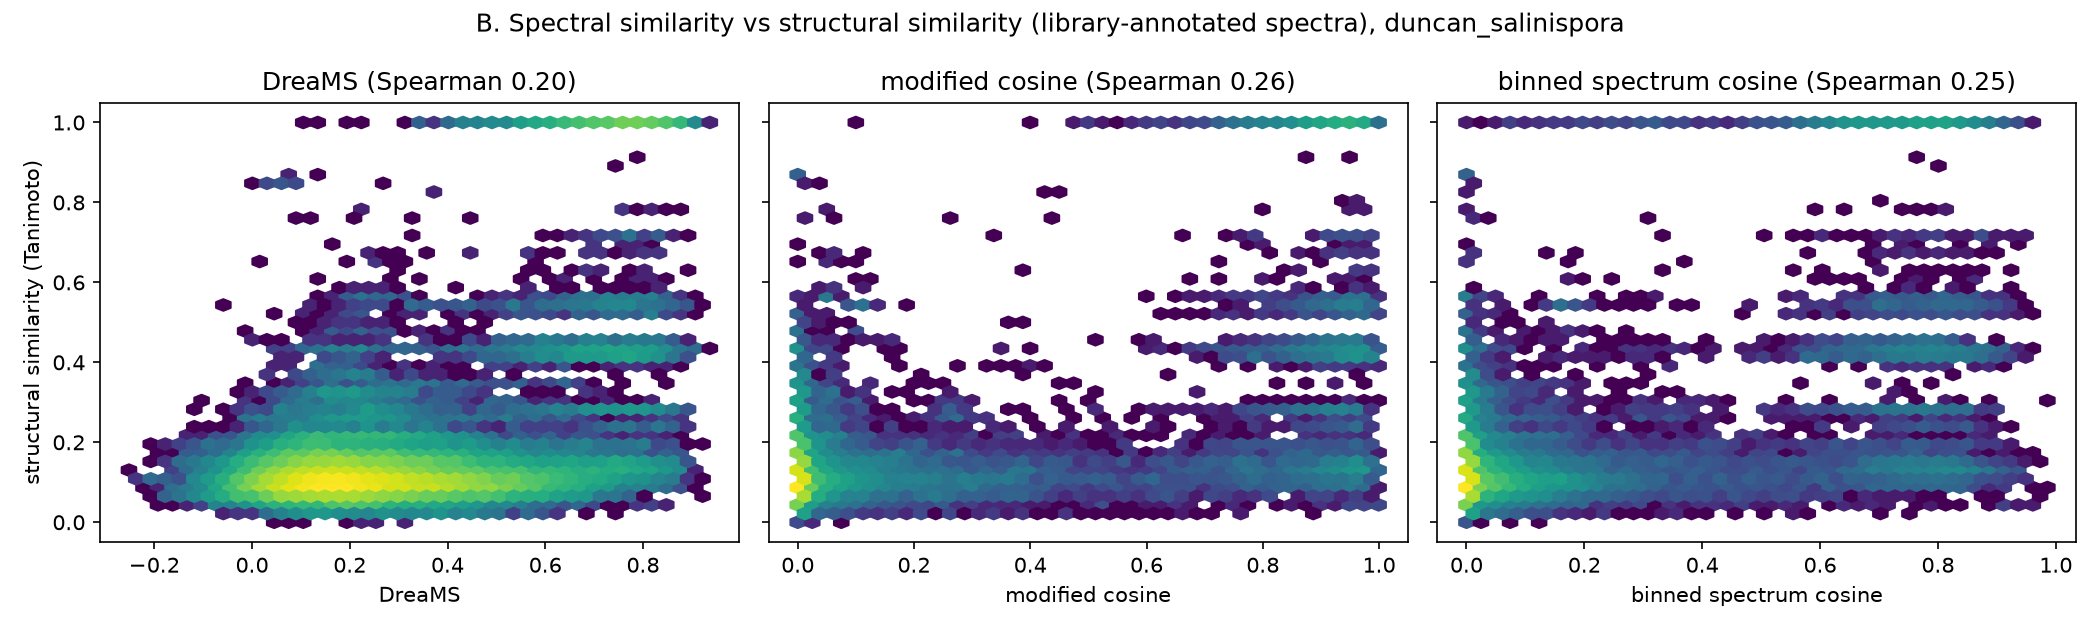

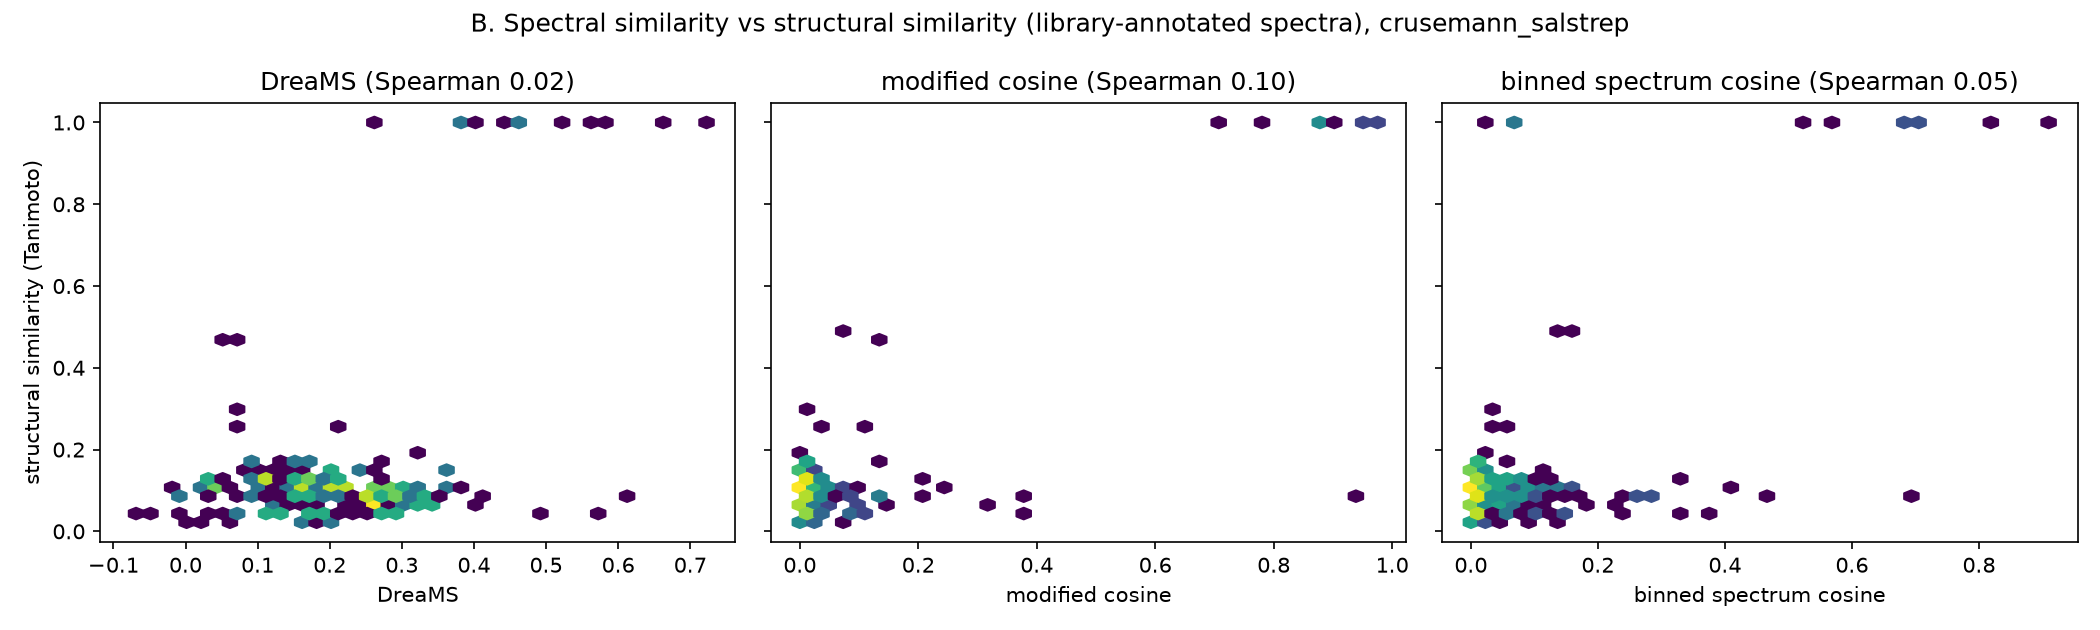

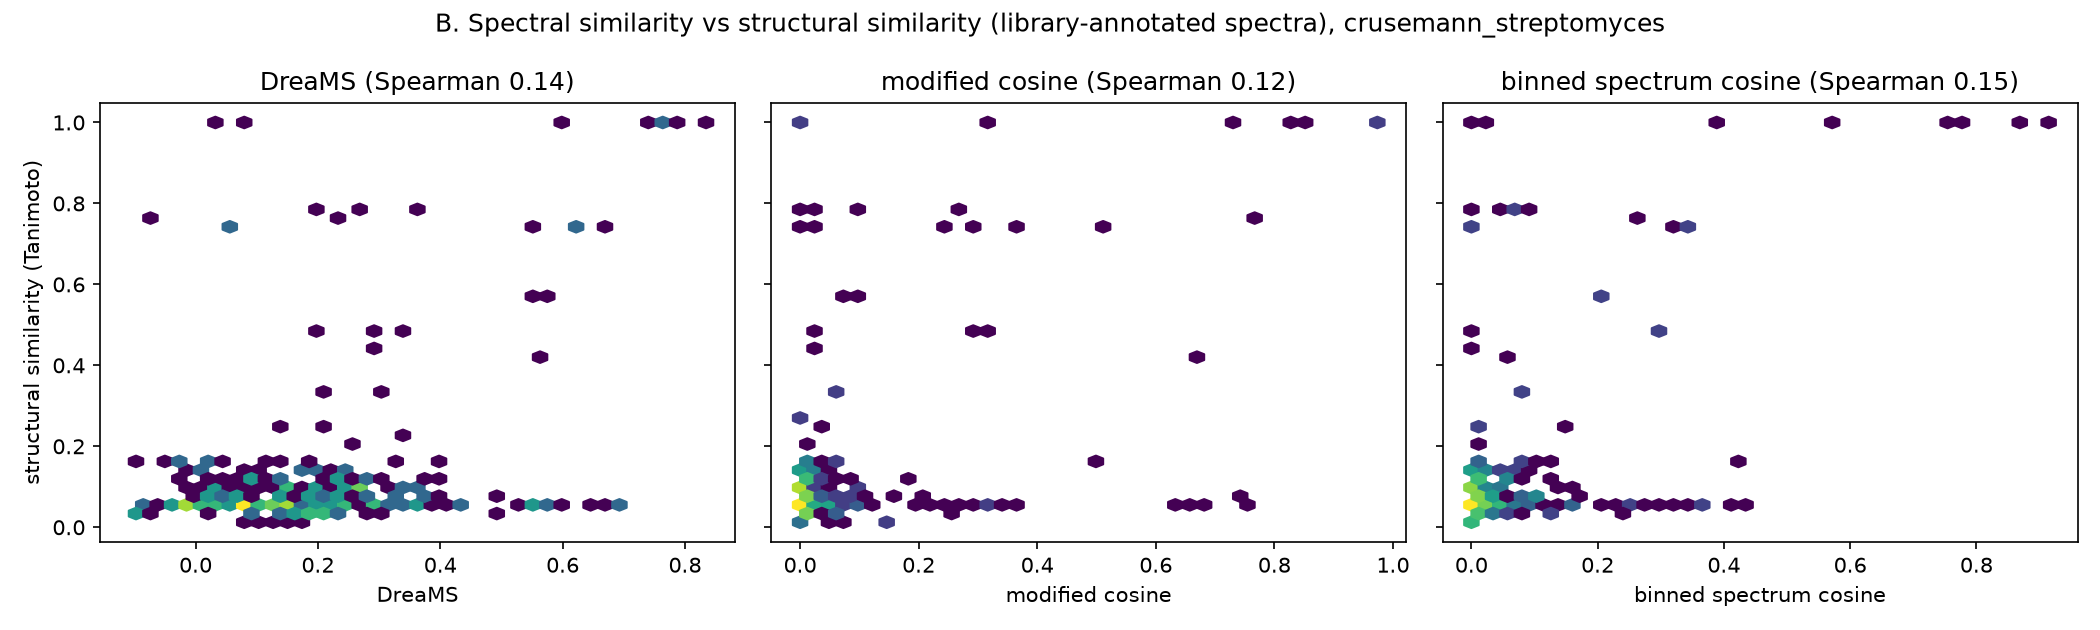

In [7]:
for run in RUNS:
    step("exp_b_structures.py", "--run", run)

display(side_by_side("exp_b_summary"))
for run in RUNS:
    figure = EXPERIMENT_DIR / "runs" / run / "results" / "exp_b_structure.png"
    if figure.exists():
        display(Image(figure, width=900))

## 5. All results in one page

`scripts/report.py` writes `RESULTS.md` with the tables and figures of every run.

In [8]:
step("report.py", "--runs", *RUNS)

done: report.py --runs duncan_salinispora crusemann_salstrep crusemann_streptomyces (1 s)


## 6. How to read the results

Write your own interpretation here before the meeting. Some guiding questions:
- In A1, is DreaMS clearly above the binned cosine, the precursor m/z baseline and the random level? Is it the same in the three datasets?
- In A3/A4, which threshold gives families that look like the GNPS families? What happens to the largest family?
- In B1 and B2, is DreaMS better than modified cosine, or about the same? How many annotated spectra does each dataset have?
- Do some links in `exp_a_new_links.parquet` make chemical sense? Look at the Δm/z (for example +14 = CH2, +16 = O) and at the library names.

**My interpretation:** *(write here)*

## 7. Limitations

1. **GNPS families are not ground truth.** They come from modified cosine, so Experiment A measures agreement with GNPS.
2. **Library hits are putative.** They are spectral matches, not confirmed structures. Experiment B has few annotated spectra in the Crüsemann jobs.
3. **Data quality and resolution.** Many spectra are removed by the quality rules (see the filter reports). The GNPS jobs used fragment tolerances of 0.3 Da (Duncan) and 0.5 Da (Crüsemann), which suggests low-resolution data or wide settings, while DreaMS was pre-trained on data with high mass accuracy. Check the instruments on MassIVE. If the data are low resolution, DreaMS is used outside its training domain.
4. **Possible overlap with DreaMS training data.** These datasets are public on MassIVE, so they may be part of GeMS (DreaMS pre-training, without labels). The embedding model was also fine-tuned on spectra with known structures; if the same compounds were used, Experiment B can look better than it really is.
5. **The runs are not independent.** The SalStrep job also re-analyses the *Streptomyces* data of MSV000078839.
6. **Small numbers.** This is a first look, not a conclusion.

## 8. Open questions and next steps

**Questions for Joana and Daniel**
1. Should I keep the pre-trained DreaMS model, fine-tune it, or train a new model?
2. Which dataset should I use? Is there a high-resolution actinobacteria dataset in PRIORITY or in PoDP?
3. What is the end goal for the metabolomics layer: molecular families, linking spectra to BGCs (NPLinker), or features for a multi-omics model?

**Next steps (proposal)**
- Run this notebook on a high-resolution actinobacteria dataset (add it to `RUNS`).
- Use DreaMS families instead of GNPS families in NPLinker-style linking to gene cluster families.